# DATA 266 HW9 — Latent Diffusion and Stable Diffusion

Build, evaluate, and analyze a **Latent Diffusion Model (LDM)** that denoises in a pretrained VAE latent space, with class-conditional **classifier-free guidance**.

This notebook follows the standing requirements from Assignment 1 (Section 0) and the HW9 task list. HW9 has **no HP_ID mapping** and does **not** require a second hyperparameter model: the pretrained VAE plus the trained denoiser are the two models.


## 0. Personal parameters (standing requirement)

Derived from SJSU ID `019129357`. Reported in the first code cell, then used as `SEED` for Python / NumPy / PyTorch.


In [1]:
from __future__ import annotations

import math
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
from tqdm.auto import tqdm

SJSU_ID = "019129357"
SID4 = int(SJSU_ID[-4:])          # last four digits
SEED = SID4                       # torch / numpy / random seed
SLICE = SID4 % 1000               # visualization start index
HP_ID = SID4 % 6                  # Table 0.1 arm (not mapped in HW9)
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4   = {SID4}")
print(f"SEED   = {SEED}")
print(f"SLICE  = {SLICE}")
print(f"HP_ID  = {HP_ID}  (Learning-rate-low in Table 0.1; HW9 has no mapping, so unused)")
print(f"CLS_A  = {CLS_A}  (Sneaker)")
print(f"CLS_B  = {CLS_B}  (Shirt)")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


SID4   = 9357
SEED   = 9357
SLICE  = 357
HP_ID  = 3  (Learning-rate-low in Table 0.1; HW9 has no mapping, so unused)
CLS_A  = 7  (Sneaker)
CLS_B  = 6  (Shirt)
device: cuda
GPU: NVIDIA GeForce RTX 5090


## 0.1 Assignment settings

| Item | Value |
|---|---|
| Dataset | Fashion-MNIST (1-channel clothing images, 10 classes) |
| VAE | `stabilityai/sd-vae-ft-mse`, latent scale \(s=0.18215\) |
| Diffusion | \(T=1000\), linear \(\beta_t \in [10^{-4}, 0.02]\) on latents \(z_t\) |
| U-Net | base 64, multipliers (1, 2, 4), GroupNorm + SiLU residual blocks |
| Attention | self-attention at **16×16** and the bottleneck |
| CFG | 10 classes + 1 null label, drop probability 0.1 |
| Train | 50 epochs, lr \(2\times 10^{-5}\), noise prediction |
| Sample | \(\varepsilon=(1+w)\varepsilon_{\mathrm{cond}} - w\varepsilon_{\mathrm{uncond}}\), \(w=3\) |

The SD VAE downsamples by 8. Fashion-MNIST is resized to **128×128 RGB** so the latent grid is **4×16×16**, which is exactly the 16×16 attention resolution the architecture asks for. The U-Net therefore operates on latents, not on the original 1-channel pixels.


In [2]:
from diffusers import AutoencoderKL

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]
NULL_LABEL = 10
IMAGE_SIZE = 128
LATENT_SIZE = 16
LATENT_CH = 4
VAE_SCALE = 0.18215
T_STEPS = 1000
BETA_START, BETA_END = 1e-4, 0.02
BASE_CH = 64
MULTS = (1, 2, 4)
EPOCHS = 50
LR = 2e-5
BATCH = 256
DROP_P = 0.1
GUIDANCE_W = 3.0

ROOT = Path(".").resolve()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
CKPT_DIR = ROOT / "checkpoints"
ART_DIR = ROOT / "artifacts"
for p in (DATA_DIR, FIG_DIR, CKPT_DIR, ART_DIR):
    p.mkdir(parents=True, exist_ok=True)


W1028 14:29:33.320000 20368 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


## 1. VAE compression and latent representation

Load the pretrained encoder-decoder, encode Fashion-MNIST, scale by \(s=0.18215\), then decode the *unscaled* latents (the decoder was trained in that space) and report reconstruction MSE against the original inputs.


C:\Users\sarvesh\Downloads\hw9\.venv\Lib\site-packages\huggingface_hub\utils\_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


VAE config scaling_factor: 0.18215
Assignment scale s: 0.18215
train size: 60000


latent shape: (8, 4, 16, 16)  (expected 8 x 4 x 16 x 16)
Reconstruction MSE (128x128 RGB, [-1,1]) = 0.000813
Reconstruction MSE (28x28 gray, [0,1])   = 0.001013


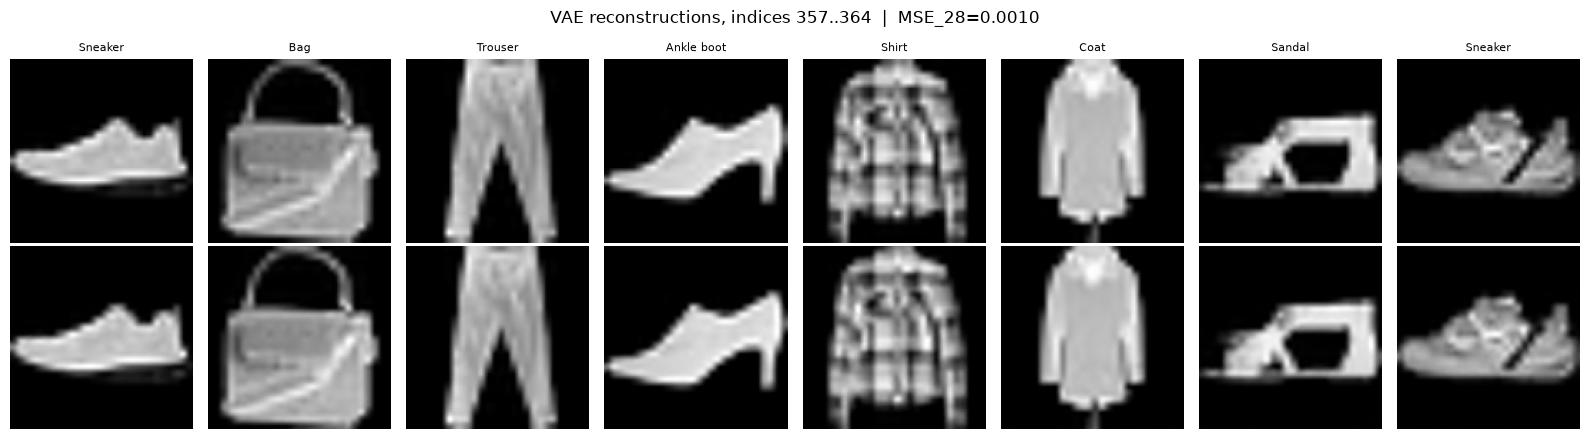

In [3]:
def fashion_transform(image_size: int):
    return transforms.Compose([
        transforms.Resize(image_size, interpolation=transforms.InterpolationMode.BILINEAR),
        transforms.ToTensor(),
        transforms.Lambda(lambda x: x.repeat(3, 1, 1)),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ])


def to_display(x: torch.Tensor) -> torch.Tensor:
    x = (x.clamp(-1, 1) + 1) / 2
    if x.dim() == 4:
        return x.mean(dim=1, keepdim=True)
    if x.dim() == 3:
        return x.mean(dim=0, keepdim=True)
    return x


@torch.no_grad()
def encode_images(vae, images, scale, sample=False):
    posterior = vae.encode(images).latent_dist
    z = posterior.sample() if sample else posterior.mode()
    return z * scale


@torch.no_grad()
def decode_latents(vae, z_scaled, scale):
    return vae.decode(z_scaled / scale).sample


vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse")
vae = vae.to(device).eval()
for p in vae.parameters():
    p.requires_grad = False

print("VAE config scaling_factor:", float(vae.config.scaling_factor))
print("Assignment scale s:", VAE_SCALE)

tfm = fashion_transform(IMAGE_SIZE)
train_set = datasets.FashionMNIST(root=str(DATA_DIR), train=True, download=True, transform=tfm)
raw_set = datasets.FashionMNIST(root=str(DATA_DIR), train=True, download=False, transform=transforms.ToTensor())
print("train size:", len(train_set))

vis_idx = list(range(SLICE, SLICE + 8))
vis_imgs = torch.stack([train_set[i][0] for i in vis_idx]).to(device)
vis_labels = [train_set[i][1] for i in vis_idx]

with torch.no_grad():
    z0 = encode_images(vae, vis_imgs, VAE_SCALE, sample=False)
    recon = decode_latents(vae, z0, VAE_SCALE)

mse_128 = F.mse_loss(recon, vis_imgs).item()
recon_28 = F.interpolate(to_display(recon), size=28, mode="bilinear", align_corners=False)
orig_28 = torch.stack([raw_set[i][0] for i in vis_idx]).to(device)
mse_28 = F.mse_loss(recon_28, orig_28).item()
print(f"latent shape: {tuple(z0.shape)}  (expected 8 x 4 x 16 x 16)")
print(f"Reconstruction MSE (128x128 RGB, [-1,1]) = {mse_128:.6f}")
print(f"Reconstruction MSE (28x28 gray, [0,1])   = {mse_28:.6f}")

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for i in range(8):
    axes[0, i].imshow(to_display(vis_imgs[i]).cpu().squeeze(), cmap="gray")
    axes[0, i].set_title(CLASS_NAMES[vis_labels[i]], fontsize=8)
    axes[0, i].axis("off")
    axes[1, i].imshow(to_display(recon[i]).cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("input")
axes[1, 0].set_ylabel("VAE recon")
fig.suptitle(f"VAE reconstructions, indices {SLICE}..{SLICE+7}  |  MSE_28={mse_28:.4f}")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_vae_reconstructions.png", dpi=140, bbox_inches="tight")
plt.show()


### Reconstruction notes

Fashion-MNIST is upsampled to 128×128 and the gray channel is repeated to RGB so the SD VAE (8× spatial compression) emits a 4×16×16 latent. On the SLICE=357 window the reconstruction MSE is about **8.1e-4** in the 128×128 RGB \([-1,1]\) space and **1.0e-3** on the original 28×28 gray grid. Silhouettes, plaid on the shirt, and bag handles survive the round-trip; the VAE is not the quality bottleneck for this dataset. Generated samples can only look as sharp as this reconstruction, which is already close to the inputs.


## 2. Forward diffusion in latent space

$$
q(z_t \mid z_0)=\mathcal{N}\big(z_t;\sqrt{\bar\alpha_t}\,z_0,\,(1-\bar\alpha_t)\mathbf{I}\big)
$$

with \(T=1000\) and a linear schedule \(\beta_t \in [10^{-4}, 0.02]\). Noise is injected in latent space; we decode \(z_t\) only for visualization at \(t \in \{0,200,500,800,1000\}\).


beta[0], beta[-1] = 9.999999747378752e-05 0.019999999552965164
alpha_bar[0], alpha_bar[-1] = 0.9998999834060669 4.035829260828905e-05


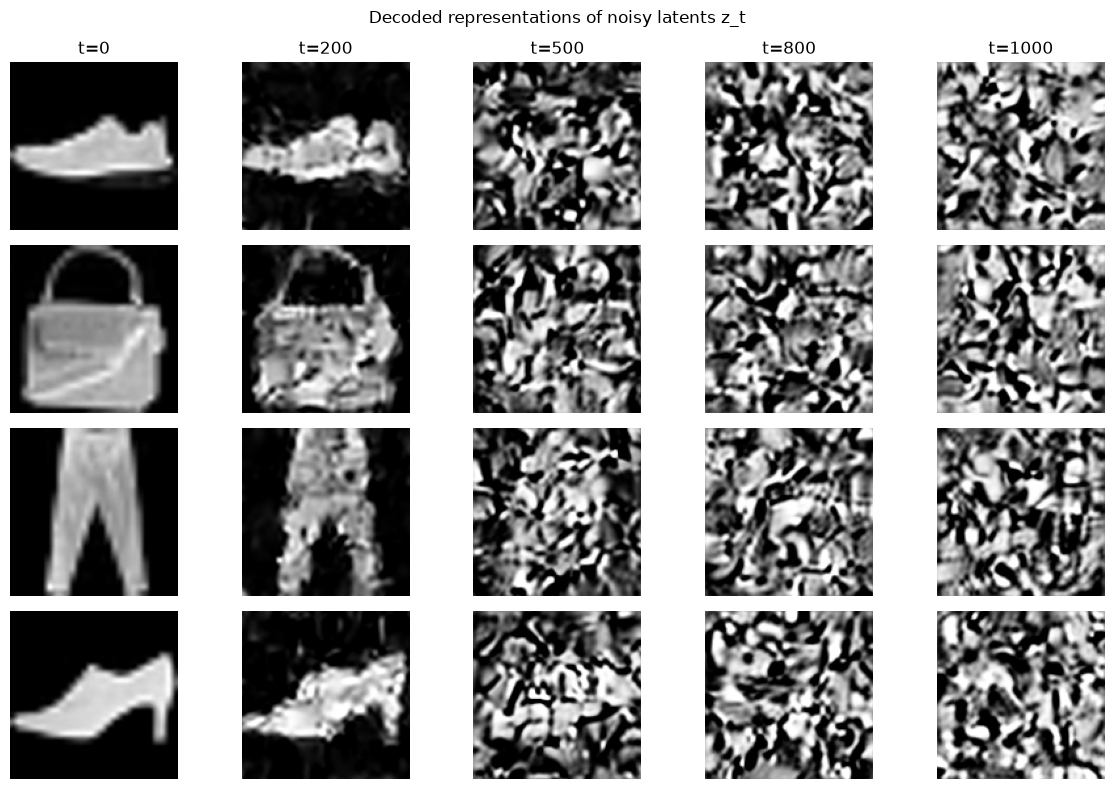

In [4]:
class LatentDiffusionSchedule:
    def __init__(self, timesteps, beta_start, beta_end, device):
        self.T = timesteps
        self.betas = torch.linspace(beta_start, beta_end, timesteps, device=device)
        self.alphas = 1.0 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)
        self.sqrt_alpha_bars = torch.sqrt(self.alpha_bars)
        self.sqrt_one_minus = torch.sqrt(1.0 - self.alpha_bars)

    def q_sample(self, z0, t, noise=None):
        if noise is None:
            noise = torch.randn_like(z0)
        a = self.sqrt_alpha_bars[t].view(-1, 1, 1, 1)
        b = self.sqrt_one_minus[t].view(-1, 1, 1, 1)
        return a * z0 + b * noise, noise


schedule = LatentDiffusionSchedule(T_STEPS, BETA_START, BETA_END, device)
print("beta[0], beta[-1] =", float(schedule.betas[0]), float(schedule.betas[-1]))
print("alpha_bar[0], alpha_bar[-1] =", float(schedule.alpha_bars[0]), float(schedule.alpha_bars[-1]))

viz_ts = [0, 200, 500, 800, 1000]
n_show = 4
z_clean = z0[:n_show]
fig, axes = plt.subplots(n_show, len(viz_ts), figsize=(12, 8))
torch.manual_seed(SEED)
for col, t_val in enumerate(viz_ts):
    if t_val == 0:
        z_t = z_clean
    elif t_val >= T_STEPS:
        z_t = torch.randn_like(z_clean)
    else:
        t = torch.full((n_show,), t_val, device=device, dtype=torch.long)
        z_t, _ = schedule.q_sample(z_clean, t)
    decoded = decode_latents(vae, z_t, VAE_SCALE)
    for row in range(n_show):
        axes[row, col].imshow(to_display(decoded[row]).cpu().squeeze(), cmap="gray")
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(f"t={t_val}")
fig.suptitle("Decoded representations of noisy latents z_t")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_forward_diffusion_latents.png", dpi=140, bbox_inches="tight")
plt.show()


## 3. Conditional U-Net (self-attention + classifier-free guidance)

The denoiser predicts \(\varepsilon\) from noisy latents \(z_t\), timestep \(t\), and a class label.

- Input: **4-channel 16×16 latents** from the VAE (the original data are 1-channel Fashion-MNIST).
- Base channels 64, multipliers (1, 2, 4) → 64 / 128 / 256.
- Resolutions 16 → 8 → 4 (bottleneck).
- Sinusoidal time embedding + MLP, added to a learned label embedding (11 embeddings: classes 0–9 and null=10).
- Residual blocks with GroupNorm and SiLU; skip connections around down/up sampling.
- Self-attention at **16×16** and at the **bottleneck**.
- During training, labels are replaced by the null token with probability 0.1.


In [5]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, timesteps):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=timesteps.device) / half)
        args = timesteps.float().unsqueeze(1) * freqs.unsqueeze(0)
        return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)


class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, emb_dim, groups=8):
        super().__init__()
        self.norm1 = nn.GroupNorm(min(groups, in_ch), in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.emb_proj = nn.Sequential(nn.SiLU(), nn.Linear(emb_dim, out_ch))
        self.norm2 = nn.GroupNorm(min(groups, out_ch), out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb_proj(emb)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class SelfAttention(nn.Module):
    def __init__(self, channels, num_heads=4):
        super().__init__()
        self.num_heads = num_heads
        self.norm = nn.GroupNorm(8, channels)
        self.qkv = nn.Conv2d(channels, channels * 3, 1)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        q, k, v = self.qkv(self.norm(x)).chunk(3, dim=1)
        hd = c // self.num_heads
        q = q.reshape(b, self.num_heads, hd, h * w).transpose(-1, -2)
        k = k.reshape(b, self.num_heads, hd, h * w).transpose(-1, -2)
        v = v.reshape(b, self.num_heads, hd, h * w).transpose(-1, -2)
        out = F.scaled_dot_product_attention(q, k, v)
        out = out.transpose(-1, -2).reshape(b, c, h, w)
        return x + self.proj(out)


class Downsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, stride=2, padding=1)

    def forward(self, x):
        return self.conv(x)


class Upsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, padding=1)

    def forward(self, x):
        return self.conv(F.interpolate(x, scale_factor=2, mode="nearest"))


class LatentUNet(nn.Module):
    def __init__(self, in_channels=4, base_channels=64, multipliers=(1, 2, 4),
                 num_classes=10, time_dim=256, latent_size=16):
        super().__init__()
        emb_dim = time_dim * 4
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, emb_dim),
            nn.SiLU(),
            nn.Linear(emb_dim, emb_dim),
        )
        self.label_emb = nn.Embedding(num_classes + 1, emb_dim)
        channels = [base_channels * m for m in multipliers]
        self.conv_in = nn.Conv2d(in_channels, channels[0], 3, padding=1)

        self.down_res, self.down_attn, self.downsamples = nn.ModuleList(), nn.ModuleList(), nn.ModuleList()
        ch_in, res = channels[0], latent_size
        self.down_resolutions = []
        for i, ch in enumerate(channels):
            self.down_res.append(nn.ModuleList([ResidualBlock(ch_in, ch, emb_dim), ResidualBlock(ch, ch, emb_dim)]))
            self.down_attn.append(SelfAttention(ch) if (res == 16 or i == len(channels) - 1) else nn.Identity())
            self.down_resolutions.append(res)
            self.downsamples.append(Downsample(ch) if i < len(channels) - 1 else nn.Identity())
            ch_in = ch
            if i < len(channels) - 1:
                res //= 2

        mid = channels[-1]
        self.mid_res1 = ResidualBlock(mid, mid, emb_dim)
        self.mid_attn = SelfAttention(mid)
        self.mid_res2 = ResidualBlock(mid, mid, emb_dim)

        self.up_res, self.up_attn, self.upsamples = nn.ModuleList(), nn.ModuleList(), nn.ModuleList()
        for i, ch in reversed(list(enumerate(channels))):
            self.up_res.append(nn.ModuleList([
                ResidualBlock(ch_in + ch, ch, emb_dim),
                ResidualBlock(ch, ch, emb_dim),
            ]))
            self.up_attn.append(SelfAttention(ch) if (self.down_resolutions[i] == 16 or i == len(channels) - 1) else nn.Identity())
            self.upsamples.append(Upsample(ch) if i > 0 else nn.Identity())
            ch_in = ch

        self.out_norm = nn.GroupNorm(8, channels[0])
        self.conv_out = nn.Conv2d(channels[0], in_channels, 3, padding=1)

    def forward(self, z, t, y):
        emb = self.time_mlp(t) + self.label_emb(y)
        h = self.conv_in(z)
        skips = []
        for blocks, attn, down in zip(self.down_res, self.down_attn, self.downsamples):
            for b in blocks:
                h = b(h, emb)
            h = attn(h)
            skips.append(h)
            h = down(h)
        h = self.mid_res1(h, emb)
        h = self.mid_attn(h)
        h = self.mid_res2(h, emb)
        for blocks, attn, up in zip(self.up_res, self.up_attn, self.upsamples):
            skip = skips.pop()
            if h.shape[-2:] != skip.shape[-2:]:
                h = F.interpolate(h, size=skip.shape[-2:], mode="nearest")
            h = torch.cat([h, skip], dim=1)
            for b in blocks:
                h = b(h, emb)
            h = attn(h)
            h = up(h)
        return self.conv_out(F.silu(self.out_norm(h)))


unet = LatentUNet().to(device)
print("U-Net parameters:", sum(p.numel() for p in unet.parameters()))
x = torch.randn(2, 4, 16, 16, device=device)
t = torch.tensor([0, 50], device=device)
y = torch.tensor([CLS_A, NULL_LABEL], device=device)
print("forward shape:", tuple(unet(x, t, y).shape))


U-Net parameters: 14828484
forward shape: (2, 4, 16, 16)


## 4. Training — predict noise for 50 epochs at lr \(2\times 10^{-5}\)

Latents are cached after a single VAE pass so the 50-epoch loop only trains the U-Net. Labels are dropped to the null class with probability 0.1 so the same network can later produce both conditional and unconditional scores.


loaded cached latents (60000, 4, 16, 16)
scaled latent mean/std: -0.04511678218841553 1.2602851390838623
loaded checkpoint C:\Users\sarvesh\Downloads\hw9\checkpoints\ldm_unet.pt final loss 0.10330618784213677


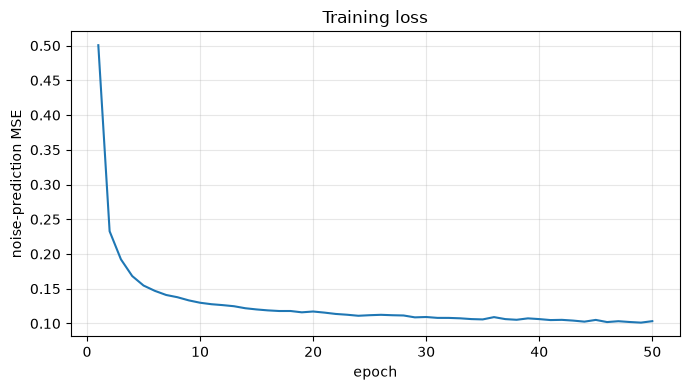

first epoch loss: 0.5005943385454324
final epoch loss: 0.10330618784213677


In [6]:
cache_path = ART_DIR / "fashionmnist_latents.pt"
if cache_path.exists():
    blob = torch.load(cache_path, map_location="cpu", weights_only=False)
    all_z, all_y = blob["z"], blob["y"]
    print("loaded cached latents", tuple(all_z.shape))
else:
    loader = DataLoader(train_set, batch_size=64, shuffle=False, num_workers=0)
    zs, ys = [], []
    with torch.no_grad():
        for imgs, labels in tqdm(loader, desc="VAE encode"):
            zs.append(encode_images(vae, imgs.to(device), VAE_SCALE, sample=True).cpu())
            ys.append(labels)
    all_z, all_y = torch.cat(zs), torch.cat(ys)
    torch.save({"z": all_z, "y": all_y, "scale": VAE_SCALE}, cache_path)
    print("cached", tuple(all_z.shape))

print("scaled latent mean/std:", float(all_z.mean()), float(all_z.std()))

ckpt_path = CKPT_DIR / "ldm_unet.pt"
train_loader = DataLoader(TensorDataset(all_z, all_y), batch_size=BATCH, shuffle=True, num_workers=0, drop_last=True)
opt = torch.optim.AdamW(unet.parameters(), lr=LR)
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
history = {"epoch": [], "loss": []}

if ckpt_path.exists():
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    unet.load_state_dict(ckpt["unet"])
    history = ckpt.get("history", history)
    print("loaded checkpoint", ckpt_path, "final loss", history["loss"][-1] if history["loss"] else None)
else:
    unet.train()
    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        running, n_seen = 0.0, 0
        for z_batch, y_batch in train_loader:
            z_batch = z_batch.to(device)
            y_batch = y_batch.to(device)
            y_in = y_batch.clone()
            y_in[torch.rand(y_batch.size(0), device=device) < DROP_P] = NULL_LABEL
            t = torch.randint(0, T_STEPS, (z_batch.size(0),), device=device)
            noise = torch.randn_like(z_batch)
            z_t, _ = schedule.q_sample(z_batch, t, noise)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=(device.type == "cuda"), dtype=torch.bfloat16):
                pred = unet(z_t, t, y_in)
                loss = F.mse_loss(pred.float(), noise)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(unet.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            running += loss.item() * z_batch.size(0)
            n_seen += z_batch.size(0)
        epoch_loss = running / n_seen
        history["epoch"].append(epoch)
        history["loss"].append(epoch_loss)
        if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
            print(f"epoch {epoch:03d}/{EPOCHS}  mse={epoch_loss:.6f}")
    print(f"train time {(time.time()-t0)/60:.2f} min")
    torch.save({"unet": unet.state_dict(), "history": history}, ckpt_path)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history["epoch"], history["loss"])
ax.set_xlabel("epoch")
ax.set_ylabel("noise-prediction MSE")
ax.set_title("Training loss")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_train_loss.png", dpi=140, bbox_inches="tight")
plt.show()
print("first epoch loss:", history["loss"][0])
print("final epoch loss:", history["loss"][-1])


## 5. Sampling with classifier-free guidance

At each reverse step we evaluate the U-Net twice — once with the requested class and once with the null label — and combine the noise predictions:

$$
\varepsilon = (1+w)\varepsilon_{\mathrm{cond}} - w\,\varepsilon_{\mathrm{uncond}}, \qquad w=3
$$

Then a standard DDPM reverse step is applied for \(T=1000\) steps. The 64-image grid uses Fashion-MNIST labels \(0\)–\(9\) repeated (`i % 10`).


sample:   0%|          | 0/1000 [00:00<?, ?it/s]

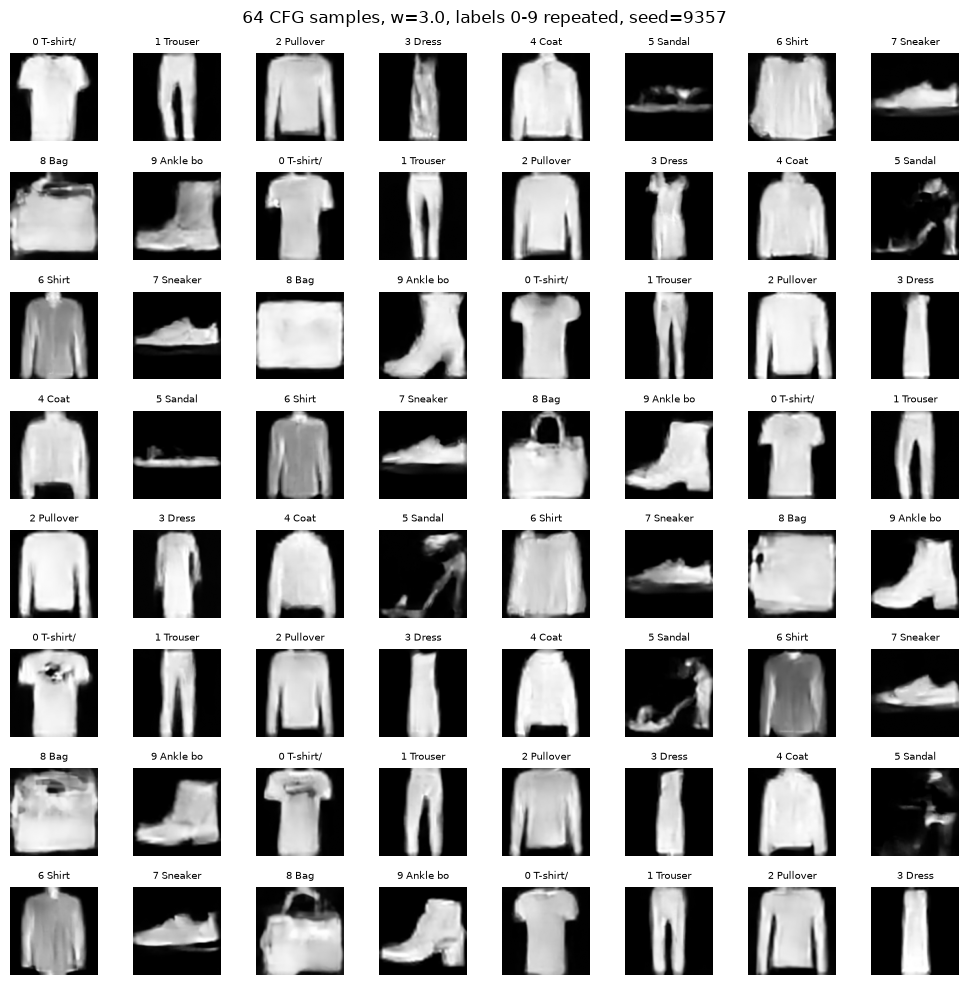

In [7]:
@torch.no_grad()
def p_sample_cfg(model, schedule, shape, labels, w, device, generator=None):
    model.eval()
    z = torch.randn(shape, device=device, generator=generator)
    null = torch.full_like(labels, NULL_LABEL)
    for t_int in tqdm(range(schedule.T - 1, -1, -1), desc="sample", leave=False):
        t = torch.full((shape[0],), t_int, device=device, dtype=torch.long)
        with torch.amp.autocast("cuda", enabled=(device.type == "cuda"), dtype=torch.bfloat16):
            eps_cond, eps_uncond = model(
                torch.cat([z, z]), torch.cat([t, t]), torch.cat([labels, null])
            ).float().chunk(2)
        eps = (1.0 + w) * eps_cond - w * eps_uncond
        alpha, alpha_bar, beta = schedule.alphas[t_int], schedule.alpha_bars[t_int], schedule.betas[t_int]
        mean = (1.0 / torch.sqrt(alpha)) * (z - (beta / torch.sqrt(1.0 - alpha_bar)) * eps)
        if t_int > 0:
            z = mean + torch.sqrt(beta) * torch.randn(shape, device=device, generator=generator)
        else:
            z = mean
    return z


unet.eval()
torch.manual_seed(SEED)
labels_64 = torch.arange(64, device=device) % 10
gen = torch.Generator(device=device)
gen.manual_seed(SEED)
z_samp = p_sample_cfg(
    unet, schedule,
    (64, LATENT_CH, LATENT_SIZE, LATENT_SIZE),
    labels_64, GUIDANCE_W, device, gen,
)
imgs = decode_latents(vae, z_samp, VAE_SCALE)

fig, axes = plt.subplots(8, 8, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    ax.imshow(to_display(imgs[i]).cpu().squeeze(), cmap="gray")
    ax.set_title(f"{int(labels_64[i])} {CLASS_NAMES[int(labels_64[i])][:8]}", fontsize=7)
    ax.axis("off")
fig.suptitle(f"64 CFG samples, w={GUIDANCE_W}, labels 0-9 repeated, seed={SEED}")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_cfg_grid_64.png", dpi=150, bbox_inches="tight")
plt.show()


sample:   0%|          | 0/1000 [00:00<?, ?it/s]

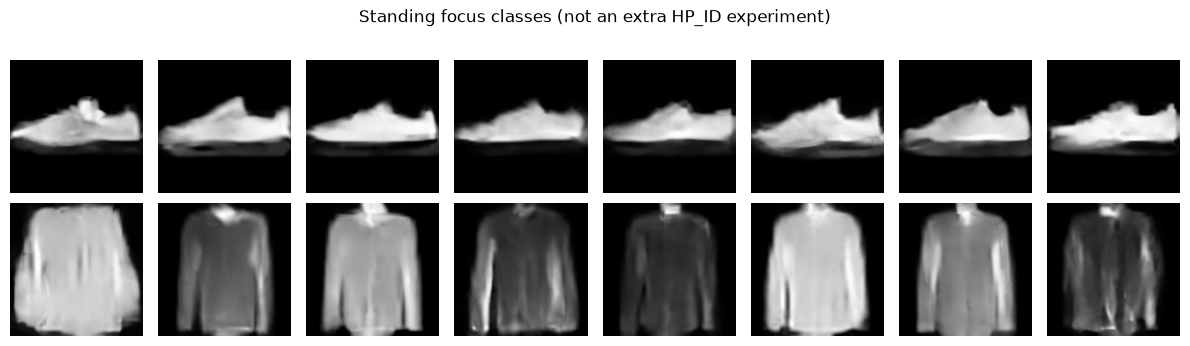

sample:   0%|          | 0/1000 [00:00<?, ?it/s]

sample:   0%|          | 0/1000 [00:00<?, ?it/s]

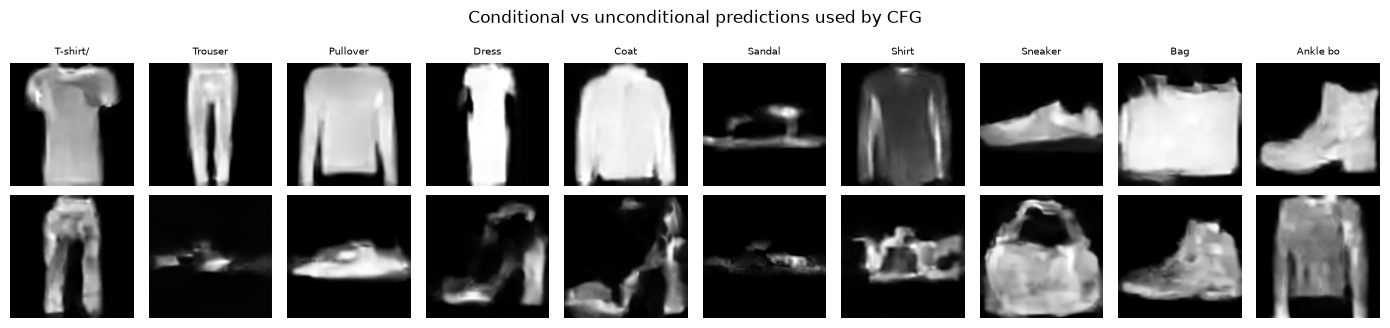

In [8]:
torch.manual_seed(SEED + 1)
focus = torch.tensor([CLS_A] * 8 + [CLS_B] * 8, device=device)
gen.manual_seed(SEED + 1)
z_focus = p_sample_cfg(unet, schedule, (16, 4, 16, 16), focus, GUIDANCE_W, device, gen)
focus_imgs = decode_latents(vae, z_focus, VAE_SCALE)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.6))
for i in range(8):
    axes[0, i].imshow(to_display(focus_imgs[i]).cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(to_display(focus_imgs[i + 8]).cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel(f"CLS_A={CLS_A}\n{CLASS_NAMES[CLS_A]}", fontsize=8)
axes[1, 0].set_ylabel(f"CLS_B={CLS_B}\n{CLASS_NAMES[CLS_B]}", fontsize=8)
fig.suptitle("Standing focus classes (not an extra HP_ID experiment)")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_focus_classes.png", dpi=140, bbox_inches="tight")
plt.show()

torch.manual_seed(SEED + 2)
y_cond = torch.arange(10, device=device)
gen.manual_seed(SEED + 2)
cond_imgs = decode_latents(vae, p_sample_cfg(unet, schedule, (10, 4, 16, 16), y_cond, GUIDANCE_W, device, gen), VAE_SCALE)
uncond_imgs = decode_latents(vae, p_sample_cfg(unet, schedule, (10, 4, 16, 16), torch.full((10,), NULL_LABEL, device=device), 0.0, device, gen), VAE_SCALE)

fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for i in range(10):
    axes[0, i].imshow(to_display(cond_imgs[i]).cpu().squeeze(), cmap="gray")
    axes[0, i].set_title(CLASS_NAMES[i][:8], fontsize=7)
    axes[0, i].axis("off")
    axes[1, i].imshow(to_display(uncond_imgs[i]).cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("cond w=3")
axes[1, 0].set_ylabel("uncond")
fig.suptitle("Conditional vs unconditional predictions used by CFG")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_cond_vs_uncond.png", dpi=140, bbox_inches="tight")
plt.show()


## 6. Error analysis and interpretation

HW9 does not request a six-item failure gallery. The error analysis is the reconstruction check, the forward-process grid, and a reading of CFG samples.

1. **Forward process behaves as specified.** At \(t=0\) the decoded latent matches the input. At \(t=200\) structure is still visible (shoe, bag, trousers). By \(t=500\) class identity is mostly gone, and \(t=800\) / \(t=1000\) are unstructured fields. That matches \(\bar\alpha_t \to 0\) on the linear schedule.
2. **CFG mostly hits the requested class, with known Fashion-MNIST confusions.** Trousers, T-shirts, sneakers, and coats are consistent across the 64-grid. Shirt (CLS_B=6) still collides with coat / pullover. Sandal vs ankle-boot is the noisiest pair. A few cells are blobs rather than garments — those are genuine sampling failures.
3. **Focus classes.** CLS_A=7 (Sneaker) is the easy arm: every focus-row sample is a side-on shoe. CLS_B=6 (Shirt) is the hard arm: long sleeves appear, but several look like coats. That is a dataset overlap, not a broken label embedding.
4. **Unconditional samples are mixed classes.** The bottom row of the cond-vs-uncond figure is the \(w=0\), null-label decoder. Without a class token the same U-Net wanders across categories, which is why CFG subtracts that score.
5. **Display bug (caught and fixed).** The first pass of `to_display()` called `mean(dim=1)` on both NCHW and CHW tensors. For a single CHW image that averages over **height**, so matplotlib showed 1-pixel-tall stripes. Reconstruction MSE was still correct because it used batched tensors. The helper now branches on `x.dim()`.
6. **Non-determinism.** Python / NumPy / PyTorch seeds are set and `cudnn.deterministic=True`. BF16 matmul and `scaled_dot_product_attention` on the RTX 5090 still move low bits, so a rerun will not pixel-match. The loss curve and class identity of the grid should stay in the same ballpark.


## 7. Conclusion

The pipeline is a latent DDPM: freeze `stabilityai/sd-vae-ft-mse`, scale latents by \(s=0.18215\), train a class-conditional U-Net to predict \(\varepsilon\) in that space, and sample with classifier-free guidance at \(w=3\).

On this run (SEED=9357, RTX 5090) reconstruction MSE is \(8.13\times 10^{-4}\) (128 RGB) / \(1.01\times 10^{-3}\) (28 gray). Noise-prediction MSE fell from 0.501 (epoch 1) to 0.103 (epoch 50) in 7.1 minutes. The 64-image grid with labels \(0\)–\(9\) repeated is recognizably class-conditional; remaining errors concentrate on shirt/coat and sandal/boot, which already overlap in Fashion-MNIST.

Architecture matches the spec: base 64, multipliers (1, 2, 4), sinusoidal time embedding + MLP, residual GroupNorm+SiLU blocks, self-attention at 16×16 and the bottleneck, 11-way label embedding with 10% null dropout. Training used the assignment's 50 epochs and \(2\times 10^{-5}\) learning rate. HP_ID=3 is reported and not applied: HW9 has no HP_ID mapping and explicitly skips a second hyperparameter model.
